In [1]:
#Cargamos las features y seperamos train (hasta 2018) y test (desde 2019) por fechas, dejando 8 semanas de margen, para evaluar el 
#modelo con años que nunca ha visto.

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

df = pd.read_parquet("../data/processed/features.parquet")

FEATURES = [
    "volumen", "pct_llenado", "cambio_1s", "cambio_4s",
    "lluvia", "lluvia_lag1", "lluvia_4s", "lluvia_12s", "lluvia_26s",
    "lluvia_año_hidro", "semana", "tmed", "tmed_4s",
]
OBJETIVO = "objetivo_4s"

datos = df.dropna(subset=FEATURES + [OBJETIVO])

INICIO_TEST = "2019-01-01"
train = datos[datos.index < pd.Timestamp(INICIO_TEST) - pd.Timedelta(weeks=8)]
test = datos[datos.index >= INICIO_TEST]

X_train, y_train = train[FEATURES], train[OBJETIVO]
X_test, y_test = test[FEATURES], test[OBJETIVO]

print("Train:", X_train.index.min().date(), "→", X_train.index.max().date(), len(X_train))
print("Test: ", X_test.index.min().date(), "→", X_test.index.max().date(), len(X_test))

Train: 1994-03-01 → 2018-10-30 1288
Test:  2019-01-01 → 2026-09-22 404


In [2]:
#Baselines: calculamos el error de dos modelos simples de referencia (sin cambio y media de cada semana del año), para saber qué error tiene
#que superar nuestro modelo.

resultados = {}

pred_persistencia = np.zeros(len(y_test))
resultados["Persistencia (sin cambio)"] = mean_absolute_error(y_test, pred_persistencia)

media_semana = train.groupby("semana")[OBJETIVO].mean()
pred_estacional = X_test["semana"].map(media_semana)
resultados["Media estacional"] = mean_absolute_error(y_test, pred_estacional)

pd.Series(resultados).round(1)

Persistencia (sin cambio)    174.1
Media estacional             123.2
dtype: float64

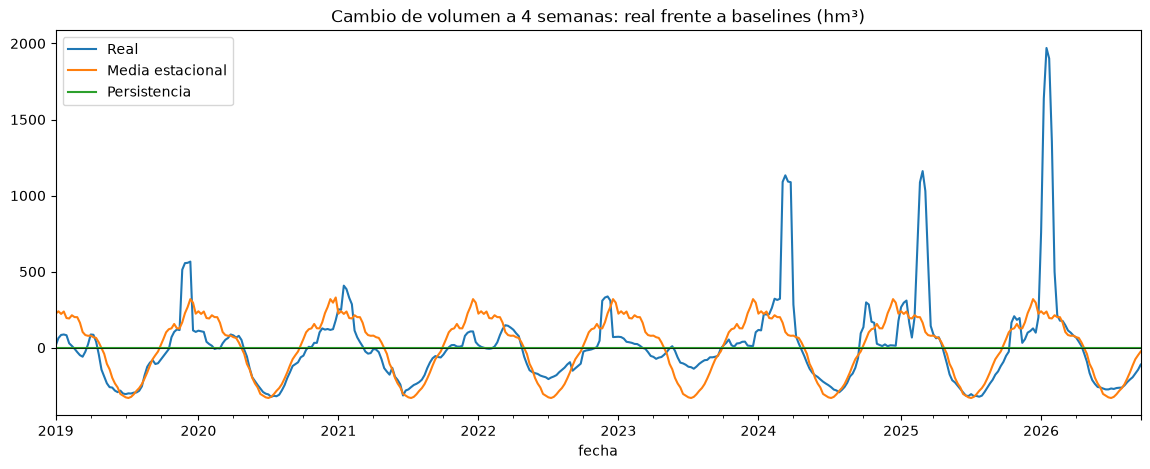

In [3]:
import matplotlib.pyplot as plt

comparacion = pd.DataFrame({
    "Real": y_test,
    "Media estacional": pred_estacional,
    "Persistencia": pred_persistencia,
}, index=y_test.index)

comparacion.plot(figsize=(14, 5), title="Cambio de volumen a 4 semanas: real frente a baselines (hm³)")
plt.axhline(0, color="black", linewidth=0.5)
plt.show()

In [4]:
# Baselines: persistencia (sin cambio) MAE 174 hm³; media estacional MAE 123 hm³.
# Solo con la época del año el error baja un 29%. El modelo tiene que bajar claramente de 123.

In [5]:
#Entrenamos una regresión lineal con las variables escaladas, para tener un primer modelo de ML y compararlo con los baselines.

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

lineal = make_pipeline(StandardScaler(), LinearRegression())
lineal.fit(X_train, y_train)

pred_lineal = lineal.predict(X_test)
resultados["Regresión lineal"] = mean_absolute_error(y_test, pred_lineal)

pd.Series(resultados).round(1)

Persistencia (sin cambio)    174.1
Media estacional             123.2
Regresión lineal             124.1
dtype: float64

In [6]:
#Añadimos la semana del año como seno y coseno, para que la regresión loneal pueda captar el ciclo anual, y comparamos resultado 

for X in (X_train, X_test):
    X["sem_sin"] = np.sin(2 * np.pi * X["semana"] / 52)
    X["sem_cos"] = np.cos(2 * np.pi * X["semana"] / 52)

lineal_ciclica = make_pipeline(StandardScaler(), LinearRegression())
lineal_ciclica.fit(X_train, y_train)

resultados["Lineal + semana cíclica"] = mean_absolute_error(y_test, lineal_ciclica.predict(X_test))
pd.Series(resultados).round(1)

Persistencia (sin cambio)    174.1
Media estacional             123.2
Regresión lineal             124.1
Lineal + semana cíclica      118.0
dtype: float64

In [7]:
# Regresión lineal: 124 (no mejora al baseline: no capta el ciclo anual con semana 1-52).
# Con semana cíclica (seno y coseno): 118, un 4% mejor que la media estacional.
# Límite: solo relaciones lineales y sin interacciones (lluvia x época).

In [8]:
#Entrenamos un Random Forest con las mismas variables, para ver si captar relaciones no lineales e interacciones mejora el error.

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
resultados["Random Forest"] = mean_absolute_error(y_test, pred_rf)
pd.Series(resultados).round(1)

Persistencia (sin cambio)    174.1
Media estacional             123.2
Regresión lineal             124.1
Lineal + semana cíclica      118.0
Random Forest                112.9
dtype: float64

In [9]:
#Comparamos el error del Random Forest en train y test, para ver si ha memorizado los datos en lugar de aprender patrones generales.

mae_train_rf = mean_absolute_error(y_train, rf.predict(X_train))
print("Random Forest - MAE train:", round(mae_train_rf, 1), "| test:", round(resultados["Random Forest"], 1))

Random Forest - MAE train: 58.3 | test: 112.9


In [10]:
#Entrenamos XGBoost con paramétros moderados para comparar el boosting con Random Forest y los baselines.

from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5, random_state=42,
)
xgb.fit(X_train, y_train)

resultados["XGBoost"] = mean_absolute_error(y_test, xgb.predict(X_test))
print("XGBoost - MAE train:", round(mean_absolute_error(y_train, xgb.predict(X_train)), 1))
pd.Series(resultados).round(1)

XGBoost - MAE train: 39.3


Persistencia (sin cambio)    174.1
Media estacional             123.2
Regresión lineal             124.1
Lineal + semana cíclica      118.0
Random Forest                112.9
XGBoost                      120.8
dtype: float64

In [11]:
#Buscamos los mejores hiperparámetros de XGBoost con validación cruzada tempoeral dentro del entrenamiento, sin tocar el test, para 
#compararlo de forma justa con Random Forest

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_xgb = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 6],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

busqueda_xgb = RandomizedSearchCV(
    XGBRegressor(random_state=42), param_xgb, n_iter=40,
    cv=tscv, scoring="neg_mean_absolute_error", random_state=42, n_jobs=-1,
)
busqueda_xgb.fit(X_train, y_train)

print("Mejores parámetros:", busqueda_xgb.best_params_)
print("MAE validación:", round(-busqueda_xgb.best_score_, 1))
resultados["XGBoost ajustado"] = mean_absolute_error(y_test, busqueda_xgb.predict(X_test))
pd.Series(resultados).round(1)

Mejores parámetros: {'subsample': 0.6, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
MAE validación: 113.1


Persistencia (sin cambio)    174.1
Media estacional             123.2
Regresión lineal             124.1
Lineal + semana cíclica      118.0
Random Forest                112.9
XGBoost                      120.8
XGBoost ajustado             113.8
dtype: float64

In [ ]:
# XGBoost por defecto: 120,8. Ajustado con RandomizedSearchCV + TimeSeriesSplit: 113,8.
# Validación 113,1 ≈ test 113,8: generaliza bien y la evaluación es fiable.
# RF y XGBoost llegan al mismo techo (~113, un 8% mejor que el baseline):
# el límite es la información disponible (lluvia futura), no el algoritmo.

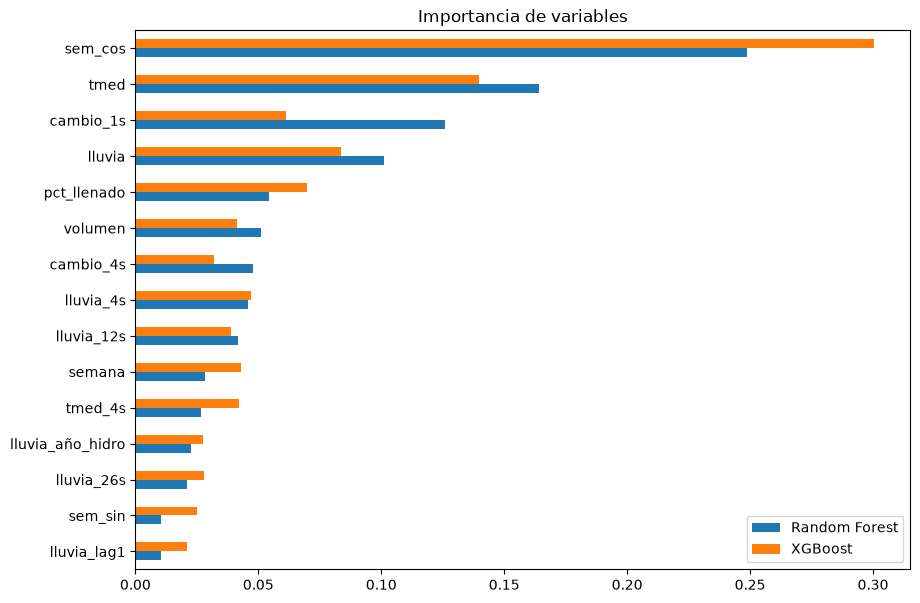

In [12]:
#Mostramos la importancia de cada variable en Random Forest y XGBoost, para ver en qué se basan sus predicciones y compararlo con el EDA.

import matplotlib.pyplot as plt

importancias = pd.DataFrame({
    "Random Forest": rf.feature_importances_,
    "XGBoost": busqueda_xgb.best_estimator_.feature_importances_,
}, index=X_train.columns).sort_values("Random Forest")

importancias.plot(kind="barh", figsize=(10, 7), title="Importancia de variables")
plt.show()

In [ ]:
# Importancia: sem_cos (invierno vs verano = llenado vs riego) es la más importante, seguida de tmed,
# cambio_1s (inercia), lluvia de la semana y el estado del embalse.
# lluvia_lag1 sale la última aunque en el EDA era la más correlacionada: su información ya está
# en cambio_1s y lluvia_4s (redundancia). Importancia baja no significa que no tenga relación.

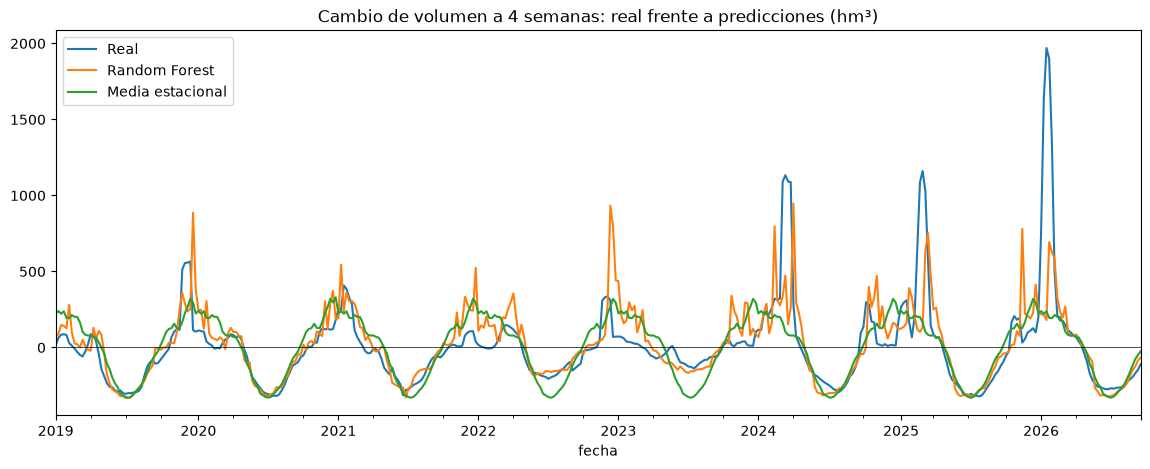

,Random Forest,Media estacional
fecha,,
2019,91.0,103.0
2020,50.0,77.0
2021,84.0,90.0
2022,101.0,109.0
2023,95.0,137.0
2024,161.0,155.0
2025,153.0,128.0
2026,187.0,211.0


In [13]:
#Comparamos la predicción del Random Forest con la realidad y con la media estacional en 1019-2026, y calculamos el error por año, para
#ver en qué situaciones mejora el modelo y en cuáles no.

comparacion = pd.DataFrame({
    "Real": y_test,
    "Random Forest": pred_rf,
    "Media estacional": pred_estacional,
}, index=y_test.index)

comparacion.plot(figsize=(14, 5), title="Cambio de volumen a 4 semanas: real frente a predicciones (hm³)")
plt.axhline(0, color="black", linewidth=0.5)
plt.show()

errores = comparacion.drop(columns="Real").sub(comparacion["Real"], axis=0).abs()
errores.groupby(errores.index.year).mean().round(0)

In [ ]:
# Error por año: el RF gana claramente en años secos y tranquilos (2023: 95 frente a 137, un 31% mejor;
# 2020: 50 frente a 77). Ha aprendido que con poca agua se riega menos y el embalse baja menos en verano.
# Pierde en años de borrascas (2024-2025): llega tarde (solo ve la lluvia cuando ya ha caído)
# y a veces sobrerreacciona (falsas alarmas con el suelo seco).
# Conclusión: es útil precisamente en sequía, que es el objetivo del proyecto.

In [15]:
#Repetimos la media estacional y el Random Forest para predecir a 8 semanas, para ver cuánto empeora el error al predecir más lejos.

OBJ8 = "objetivo_8s"
datos8 = df.dropna(subset=FEATURES + [OBJ8])
train8 = datos8[datos8.index < pd.Timestamp(INICIO_TEST) - pd.Timedelta(weeks=8)]
test8 = datos8[datos8.index >= INICIO_TEST]

X_train8, X_test8 = train8[FEATURES].copy(), test8[FEATURES].copy()
for X in (X_train8, X_test8):
    X["sem_sin"] = np.sin(2 * np.pi * X["semana"] / 52)
    X["sem_cos"] = np.cos(2 * np.pi * X["semana"] / 52)

res8 = {}
res8["Persistencia (sin cambio)"] = mean_absolute_error(test8[OBJ8], np.zeros(len(test8)))
media_sem8 = train8.groupby("semana")[OBJ8].mean()
res8["Media estacional"] = mean_absolute_error(test8[OBJ8], X_test8["semana"].map(media_sem8))

rf8 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf8.fit(X_train8, train8[OBJ8])
res8["Random Forest"] = mean_absolute_error(test8[OBJ8], rf8.predict(X_test8))

tabla = pd.DataFrame({"4 semanas": pd.Series(resultados), "8 semanas": pd.Series(res8)})
tabla.dropna().round(1)

,4 semanas,8 semanas
Media estacional,123.2,213.5
Persistencia (sin cambio),174.1,335.5
Random Forest,112.9,216.0


In [16]:
#Reentrenemaos el Random Forest con todos los datos y predecimos el volumen de la cuenca dentro de 4 semanas a partir de la última semana
#disponible, y guardamos el modelo 

import joblib

completo = df.dropna(subset=FEATURES + [OBJETIVO]).copy()
for X in (completo, df):
    X["sem_sin"] = np.sin(2 * np.pi * X["semana"] / 52)
    X["sem_cos"] = np.cos(2 * np.pi * X["semana"] / 52)

COLUMNAS = FEATURES + ["sem_sin", "sem_cos"]
modelo_final = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
modelo_final.fit(completo[COLUMNAS], completo[OBJETIVO])
joblib.dump(modelo_final, "../models/rf_objetivo_4s.joblib")

hoy = df.iloc[[-1]]
cambio = modelo_final.predict(hoy[COLUMNAS])[0]
capacidad = hoy["volumen"].iloc[0] / hoy["pct_llenado"].iloc[0] * 100

print("Fecha:", hoy.index[0].date())
print(f"Volumen actual: {hoy['volumen'].iloc[0]:.0f} hm³ ({hoy['pct_llenado'].iloc[0]:.1f}%)")
print(f"Cambio previsto en 4 semanas: {cambio:+.0f} hm³ (error típico ±113)")
print(f"Volumen previsto: {hoy['volumen'].iloc[0] + cambio:.0f} hm³ ({(hoy['volumen'].iloc[0] + cambio) / capacidad * 100:.1f}%)")

Fecha: 2026-10-20
Volumen actual: 3912 hm³ (66.9%)
Cambio previsto en 4 semanas: +55 hm³ (error típico ±113)
Volumen previsto: 3967 hm³ (67.8%)
